# Hedge design · funded experiments
**Research notebook 02 | Synthetic models | Reproducible experiments**

Explore put and collar mechanics, verify funding, select a static hedge under a premium budget, and examine model misspecification. All paths and option marks in this notebook are synthetic. A monthly model collar is not a replication of Cboe’s quarterly-put/monthly-call CLL index.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / "hedgelab").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "hedgelab").is_dir(), "Launch from the repository or notebooks directory"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.15, "font.size": 11})
pd.set_option("display.max_columns", 12)
COLORS = ["#223e5a", "#007f82", "#bd6634", "#7e739e"]

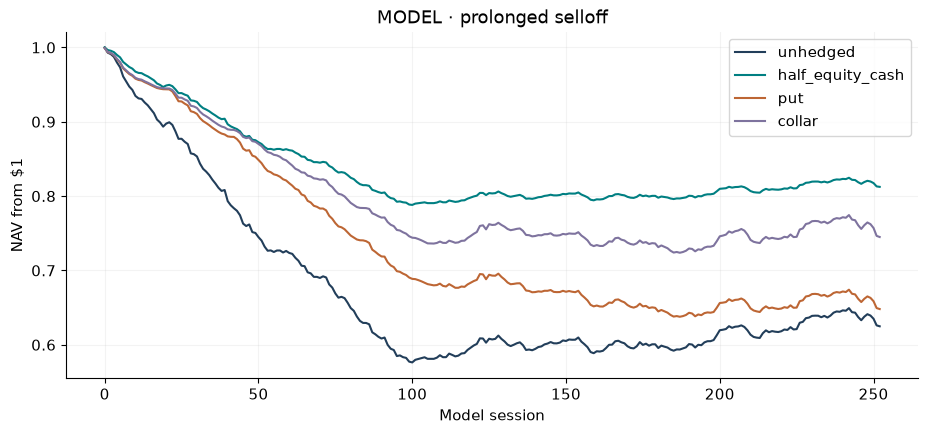

In [2]:
from hedgelab.options import scenario_paths, overlay, optimise_hedge
from hedgelab.robustness import terminal_sample, payoff, tail_metrics
SCENARIO = "prolonged_selloff"  # abrupt_crash, inflation_grind, bull_market
COVERAGE = 1.0
COST_BPS = 10
ROLL_SESSIONS = 21
spot, iv = scenario_paths(seed=42)[SCENARIO]
put = overlay(spot, iv, coverage=COVERAGE, cost_bps=COST_BPS, roll_days=ROLL_SESSIONS)
collar = overlay(spot, iv, coverage=COVERAGE, call_moneyness=1.1, cost_bps=COST_BPS, roll_days=ROLL_SESSIONS)
paths = pd.DataFrame({"unhedged": spot / spot[0], "half_equity_cash": .5 + .5 * spot / spot[0], "put": put.nav, "collar": collar.nav})
paths.plot(color=COLORS)
plt.title(f"MODEL · {SCENARIO.replace('_', ' ')}")
plt.xlabel("Model session")
plt.ylabel("NAV from $1")
plt.show()

## 1 · Reconcile every portfolio mark
Option premiums reduce the shares that can be funded. Cash plus equity plus net option value must equal NAV on every session. Calls are covered; expiry settlements precede new purchases.

In [3]:
for ledger in [put, collar]:
    reconstructed = ledger.cash + ledger.shares * ledger.spot + ledger.contracts * (ledger.put_mark - ledger.call_mark)
    np.testing.assert_allclose(ledger.nav, reconstructed, atol=1e-12)
    assert (ledger.contracts <= ledger.shares + 1e-12).all()
display(collar.iloc[[0, 20, 21, 42]][["nav", "shares", "contracts", "cash", "net_premium", "fees", "expiry_session"]])
print("Funding identity and covered-call constraint passed for both overlays.")

,nav,shares,contracts,cash,net_premium,fees,expiry_session
0,0.998999,0.009945,0.009945,-6.722053e-18,0.004499,0.001001,21
20,0.944799,0.009945,0.009945,-6.722053e-18,0.000000,0.000000,21
21,0.944706,0.010407,0.010407,-6.427964e-17,0.008755,0.000068,42
42,0.889041,0.011216,0.011216,-3.778445e-17,0.010069,0.000113,63


Funding identity and covered-call constraint passed for both overlays.


## 2 · Budget-constrained sizing
The objective is one-year terminal ES95, not path drawdown. This training sample uses a fixed 4% drift, 22% realised volatility and 22% IV. The selection budget is 2% of initial NAV; there are no static sizing costs.

In [4]:
BUDGET = .02
training = optimise_hedge(seed=142, annual_budget=BUDGET, paths=10000)
choice = training.iloc[0]
assert choice.premium_fraction <= BUDGET + 1e-12
display(training.head(8).style.format("{:.3f}"))
terminal = terminal_sample(seed=314, paths=10000)
hedged, premium = payoff(terminal, choice.strike_ratio, choice.coverage)
unhedged = terminal / 100 - 1
validation = pd.DataFrame({"selected_put": tail_metrics(hedged), "unhedged": tail_metrics(unhedged), "half_equity_cash": tail_metrics(.5 * unhedged)}).T
display(validation.style.format("{:.2%}"))

,strike_ratio,coverage,premium_fraction,terminal_ES95,mean_return
0,0.850,0.750,0.020,0.217,0.031
1,0.850,0.500,0.013,0.262,0.033
2,0.950,0.250,0.015,0.289,0.033
3,0.900,0.250,0.011,0.298,0.034
4,0.850,0.250,0.007,0.308,0.035
5,0.850,0.000,0.000,0.354,0.037
6,0.900,0.000,0.000,0.354,0.037
7,0.950,0.000,0.000,0.354,0.037


,mean_return,terminal_ES95,probability_loss,probability_loss_20pct
selected_put,3.45%,21.70%,50.86%,5.46%
unhedged,4.07%,35.46%,47.25%,13.35%
half_equity_cash,2.04%,17.73%,47.25%,0.91%


## 3 · Visualise the payoff trade-off
The independently seeded sample shares the same base assumptions. Changing the seed is not an empirical market validation.

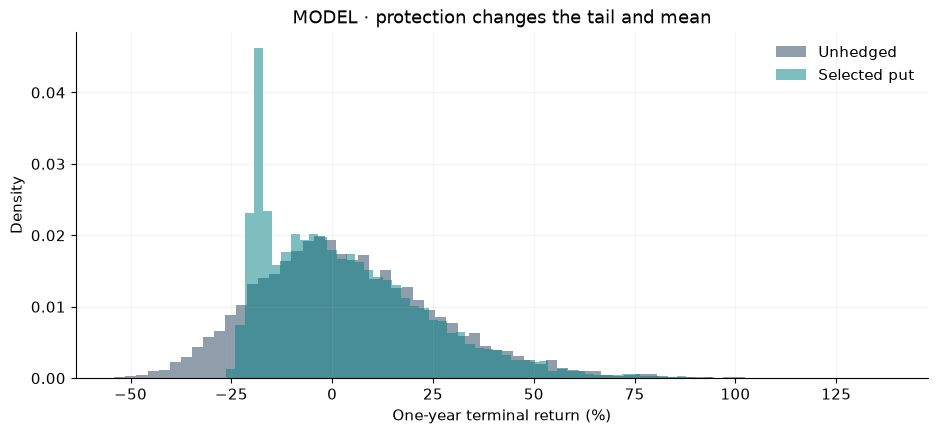

In [5]:
fig, ax = plt.subplots()
for values, label, color in [(unhedged, "Unhedged", COLORS[0]), (hedged, "Selected put", COLORS[1])]:
    ax.hist(values * 100, bins=70, density=True, alpha=.5, color=color, label=label)
ax.set(xlabel="One-year terminal return (%)", ylabel="Density", title="MODEL · protection changes the tail and mean")
ax.legend(frameon=False)
plt.show()

## 4 · Stress the assumptions, without retuning
Read all disclosed regimes and rolling sensitivities. An IV increase can make the frozen quantity unaffordable; the flag prevents an infeasible hedge from looking budget compliant.

In [6]:
regimes = pd.read_csv(ROOT / "results/robustness/model_regimes.csv")
display(regimes.loc[regimes.strategy == "selected_put", ["regime", "premium_fraction", "within_2pct_budget", "terminal_ES95", "mean_return"]].style.format({"premium_fraction":"{:.2%}", "terminal_ES95":"{:.2%}", "mean_return":"{:.2%}"}))
sweep = pd.read_csv(ROOT / "results/robustness/rolling_sensitivity.csv")
assert len(sweep) == 288
view = sweep.query("scenario == @SCENARIO and coverage == 1 and roll_days == 21")
display(view.pivot_table(index=["strategy", "iv_scale"], columns="cost_bps", values="total_return").style.format("{:.2%}"))

,regime,premium_fraction,within_2pct_budget,terminal_ES95,mean_return
0,base,1.99%,True,21.70%,3.45%
4,quiet,1.99%,True,17.76%,2.18%
8,high_realised_vol,1.99%,True,25.83%,6.05%
12,expensive_puts,4.78%,False,23.93%,0.50%
16,negative_drift,1.99%,True,23.77%,-7.54%
20,jump_stress,1.99%,True,23.46%,1.20%


## Conclusion
A hedge choice is conditional on its model, budget and objective. This notebook verifies mechanics and exposes sensitivity; it does not validate executable historical option fills. Use the [historical notebook](01_historical_evidence.ipynb) for market benchmark evidence and the [robustness notes](../results/robustness/README.md) for experiment assumptions.